# Challenge 3: Can You Change the Correlation?

**Objective:** Modify a Bell-state circuit by adding one quantum gate and compare the measurement outcomes.

**Prediction:** The original circuit will produce mostly `00` and `11`. The modified circuit will produce mostly `01` and `10`, showing opposite outcomes.

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Original Bell Circuit: {'11': 45, '00': 55}


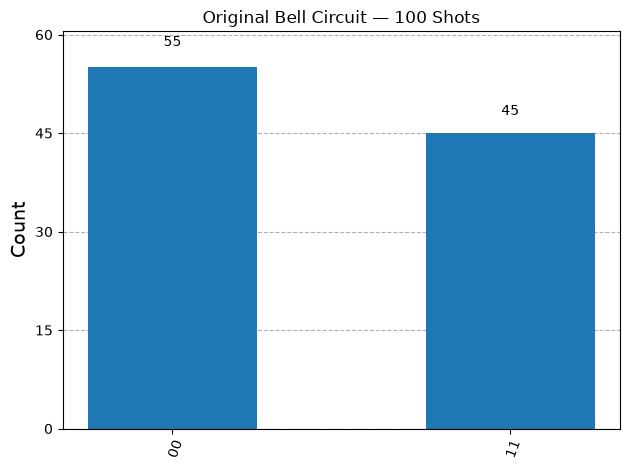

In [2]:
qc_original = QuantumCircuit(2, 2)

qc_original.h(0)
qc_original.cx(0, 1)
qc_original.measure([0, 1], [0, 1])

print(qc_original.draw())

simulator = AerSimulator()
compiled_original = transpile(qc_original, simulator)

result_original = simulator.run(
    compiled_original, shots=100
).result()

counts_original = result_original.get_counts()

print("Original Bell Circuit:", counts_original)
display(plot_histogram(
    counts_original,
    title="Original Bell Circuit — 100 Shots"
))

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 
Modified Bell Circuit: {'10': 40, '01': 60}


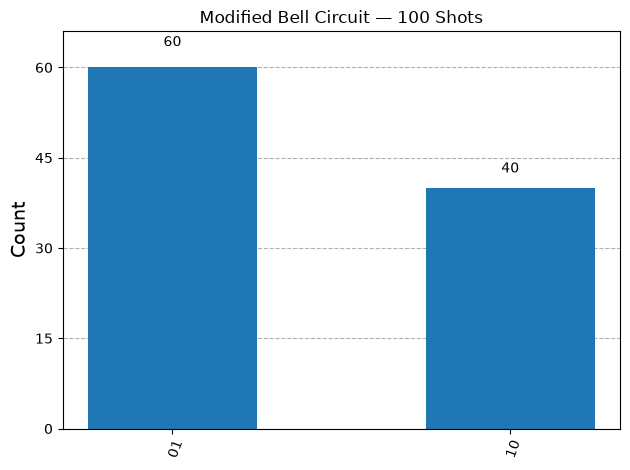

In [3]:
qc_modified = QuantumCircuit(2, 2)

qc_modified.h(0)
qc_modified.cx(0, 1)
qc_modified.x(1)
qc_modified.measure([0, 1], [0, 1])

print(qc_modified.draw())

compiled_modified = transpile(qc_modified, simulator)

result_modified = simulator.run(
    compiled_modified, shots=100
).result()

counts_modified = result_modified.get_counts()

print("Modified Bell Circuit:", counts_modified)
display(plot_histogram(
    counts_modified,
    title="Modified Bell Circuit — 100 Shots"
))

In [4]:
print("Original circuit total shots:",
      sum(counts_original.values()))

print("Modified circuit total shots:",
      sum(counts_modified.values()))

assert sum(counts_original.values()) == 100
assert sum(counts_modified.values()) == 100

print("\nOriginal circuit: 00 and 11 should dominate.")
print("Modified circuit: 01 and 10 should dominate.")
print("\nBoth circuits passed the 100-shot verification!")

Original circuit total shots: 100
Modified circuit total shots: 100

Original circuit: 00 and 11 should dominate.
Modified circuit: 01 and 10 should dominate.

Both circuits passed the 100-shot verification!



Explanation:

The original Bell circuit uses a Hadamard gate and a CNOT gate.
Its measurement outcomes are correlated, producing 00 and 11.

The modified circuit adds an X gate to qubit 1.
This flips the second qubit, changing the outcomes to 01 and 10.

Both circuits are executed for 100 shots. Small variations in
measurement counts are expected because measurements are probabilistic.

Conclusion:
Adding one X gate changes the correlation from same outcomes
to opposite outcomes while keeping the qubits entangled.
